# AwareMind EDA: the intention–behavior gap

Descriptive analysis for **Part 2 (Data Research)** of NudgeWell's Literature, Data & Technology Review (milestone 2).

- **Data:** `data/raw/awaremind/full_data_all_feature.csv`, from OSF project x6yzs (Zheng & Choe, 2026). The project has no licence attached, so this is coursework analysis only. See `data/raw/awaremind/SOURCE.md`.
- **Outputs:**
  - figures in `deliverables/02_literature_data_technology_review/figures/`;
  - every number the report quotes, in `deliverables/02_literature_data_technology_review/build/eda_summary.json`.
- **High-gap moment** (the paper's example cut-offs): an intention rating below 5.5 (leaning "stop") **and** more than 5 more minutes of phone use.

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Patch

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

RAW = Path("../data/raw/awaremind")
OUT = Path("../deliverables/02_literature_data_technology_review")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
(OUT / "build").mkdir(parents=True, exist_ok=True)

# Chart tokens: dataviz reference palette, light mode, on a white page
SURFACE = "#ffffff"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE = "#2a78d6"          # slot 1; validated with slot 2 (#eb6834): CVD dE 24.7, normal dE 33.6, contrast >= 3:1
GRAY = "#c3c2b7"          # de-emphasis

mpl.rcParams.update({
    "font.family": "Segoe UI", "font.size": 8.5,
    "axes.titlesize": 9.5, "axes.titleweight": "semibold", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": BASELINE, "axes.linewidth": 0.8,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 8,
    "savefig.dpi": 200, "savefig.bbox": "tight", "savefig.facecolor": SURFACE,
})
SUMMARY = {}  # every number the report quotes is stored here


def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion (arrays allowed)."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half


def icc1(y, groups):
    """One-way random-effects ICC(1) for unbalanced groups = share of variance that lies between participants."""
    d = pd.DataFrame({"y": np.asarray(y, float), "g": np.asarray(groups)})
    k = d.groupby("g").size()
    n_obs, n_grp = len(d), len(k)
    ssb = (k * (d.groupby("g").y.mean() - d.y.mean()) ** 2).sum()
    ssw = ((d.y - d.groupby("g").y.transform("mean")) ** 2).sum()
    msb, msw = ssb / (n_grp - 1), ssw / (n_obs - n_grp)
    k0 = (n_obs - (k**2).sum() / n_obs) / (n_grp - 1)
    return (msb - msw) / (msb + (k0 - 1) * msw)


def rounded_bars(ax, positions, values, color, horizontal=False, thickness=0.6, radius_px=4):
    """Bars with a 4px rounded data-end and a square baseline end (dataviz mark spec).
    Call after axis limits and the figure layout are final."""
    ax.figure.canvas.draw()
    inv = ax.transData.inverted()
    (x0, y0), (x1, y1) = inv.transform([(0, 0), (radius_px, radius_px)])
    rx, ry = abs(x1 - x0), abs(y1 - y0)
    colors = list(color) if isinstance(color, (list, tuple, np.ndarray)) else [color] * len(values)
    for pos, val, c in zip(positions, values, colors):
        if val <= 0:
            continue
        if horizontal:
            box = ((0, pos - thickness / 2), val, thickness)
            square = ((0, pos - thickness / 2), max(val - rx, 0), thickness)
        else:
            box = ((pos - thickness / 2, 0), thickness, val)
            square = ((pos - thickness / 2, 0), thickness, max(val - ry, 0))
        ax.add_patch(FancyBboxPatch(*box, boxstyle=f"round,pad=0,rounding_size={rx}",
                                    mutation_aspect=ry / rx, facecolor=c, edgecolor="none", linewidth=0))
        ax.add_patch(Rectangle(*square, facecolor=c, edgecolor="none", linewidth=0))


def hour_label(h):
    return "12 am" if h == 0 else f"{h} am" if h < 12 else "12 pm" if h == 12 else f"{h - 12} pm"


def records(frame, digits=2):
    return frame.reset_index().round(digits).to_dict(orient="records")

## 1. Load and audit the schema

In [2]:
df = pd.read_csv(RAW / "full_data_all_feature.csv", low_memory=False)
dictionary = (RAW / "full_data_all_feature_dictonary.md").read_text(encoding="utf-8-sig")
dict_vars = set(re.findall(r"^\| ([A-Za-z_][A-Za-z0-9_ &]*?) \|", dictionary, flags=re.M)) - {"Variable"}
undocumented = sorted(set(df.columns) - dict_vars)
absent = sorted(dict_vars - set(df.columns))

print(f"{df.shape[0]:,} rows x {df.shape[1]} columns | {df.pid.nunique()} participants")
print(f"dictionary documents {len(dict_vars)} columns")
print("in the CSV but not documented:", undocumented)
print("documented but not in the CSV:", absent)
assert df.shape == (5772, 92) and df.pid.nunique() == 37
assert (df.pid.str.lower() == df.PID.astype(str).str.lower()).all()  # PID repeats pid

duplicates = {
    "session_minutes x 60,000 = time_since_unlock (ms)": bool(np.allclose(df.session_minutes * 60000, df.time_since_unlock)),
    "session_length_till_esm = time_since_unlock": bool(np.allclose(df.session_length_till_esm, df.time_since_unlock)),
    "screen_time_so_far / 60,000 = screen_time_minutes": bool(np.allclose(df.screen_time_so_far / 60000, df.screen_time_minutes)),
}
print(duplicates)

missing = (df.isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False)
display(missing.to_frame("% missing"))

SUMMARY["dataset"] = {
    "rows": len(df), "columns": df.shape[1], "participants": df.pid.nunique(),
    "dictionary_columns": len(dict_vars), "undocumented_columns": undocumented,
    "duplicate_columns": duplicates,
    "missing_pct": missing.to_dict(),
    "missing_app_rows": int(df.Category_L1.isna().sum()),
    "unique_sessions": int(df.session_id_combined.nunique()),
    "sessions_with_multiple_checkins": int((df.groupby("session_id_combined").size() > 1).sum()),
}

5,772 rows x 92 columns | 37 participants
dictionary documents 83 columns
in the CSV but not documented: ['PID', 'date', 'host', 'pid', 'screen_time_so_far', 'session_id_combined', 'session_index', 'session_length_till_esm', 'temp_scaled']
documented but not in the CSV: []
{'session_minutes x 60,000 = time_since_unlock (ms)': True, 'session_length_till_esm = time_since_unlock': True, 'screen_time_so_far / 60,000 = screen_time_minutes': True}


,% missing
app_at_prompt,12.4
app_duration,12.4
app_total_duration_session,12.4
app_total_duration_today,12.4
Category_L1,12.4
package_name,12.4
activity_name,2.3
activity_type,2.3


## 2. Rebuild the target and check it against the paper

The dictionary says `intention_behavior_gap` is the difference between `remaining_scaled` and `answer`. Below we confirm exactly how each piece is built. The 14.9% high-gap share reported in the paper is used as a **sanity gate**: if it doesn't reproduce, nothing downstream can be trusted.

In [3]:
rl = df.remaining_log
checks = {
    "remaining_log = log10(remaining_capped + 1)": (rl - np.log10(df.remaining_capped + 1)).abs().max(),
    "intention_behavior_gap = remaining_scaled - answer": (df.intention_behavior_gap - (df.remaining_scaled - df.answer)).abs().max(),
    "temp_scaled = 10 x min-max(remaining_log)": (df.temp_scaled - 10 * (rl - rl.min()) / (rl.max() - rl.min())).abs().max(),
}
for name, diff in checks.items():
    print(f"{name}: max |diff| = {diff:.1e}")
    assert diff < 1e-9

print("corr(remaining_scaled, remaining_log) =", round(np.corrcoef(df.remaining_scaled, rl)[0, 1], 6))
print(f"mean answer = {df.answer.mean():.3f}; mean remaining_scaled = {df.remaining_scaled.mean():.3f}; max remaining_scaled = {df.remaining_scaled.max():.1f}")

df["high_gap"] = ((df.answer < 5.5) & (df.remaining_minutes > 5)).astype(int)
HG = df.high_gap.mean() * 100
print(f"high-gap moments: {df.high_gap.sum():,} of {len(df):,} = {HG:.2f}%  (paper: 14.9%)")
assert abs(HG - 14.9) < 0.1, "sanity gate failed"

SUMMARY["target"] = {
    "ibg_definition": "intention_behavior_gap = remaining_scaled - answer; remaining_scaled is log10(remaining minutes capped at ~128 + 1) rescaled linearly so its mean equals the mean answer and its maximum is 10",
    "cap_minutes": float(df.remaining_capped.max()),
    "capped_pct": (df.remaining_minutes > df.remaining_capped.max()).mean() * 100,
    "high_gap_n": int(df.high_gap.sum()), "high_gap_pct": HG,
    "stop_leaning_pct": (df.answer <= 5).mean() * 100,
    "answer_10_pct": (df.answer == 10).mean() * 100,
    "answer_1_pct": (df.answer == 1).mean() * 100,
    "answer_mean": df.answer.mean(),
    "ibg_positive_pct": (df.intention_behavior_gap > 0).mean() * 100,
    "remaining_minutes_median": df.remaining_minutes.median(),
    "remaining_minutes_mean": df.remaining_minutes.mean(),
    "remaining_over_5min_pct": (df.remaining_minutes > 5).mean() * 100,
    "remaining_over_60min_pct": (df.remaining_minutes > 60).mean() * 100,
    "remaining_max_minutes": df.remaining_minutes.max(),
}

remaining_log = log10(remaining_capped + 1): max |diff| = 4.4e-16
intention_behavior_gap = remaining_scaled - answer: max |diff| = 1.9e-15
temp_scaled = 10 x min-max(remaining_log): max |diff| = 7.1e-15
corr(remaining_scaled, remaining_log) = 1.0
mean answer = 7.102; mean remaining_scaled = 7.102; max remaining_scaled = 10.0
high-gap moments: 859 of 5,772 = 14.88%  (paper: 14.9%)


## 3. Participants, coverage and time ordering

In [4]:
df["esm_dt"] = pd.to_datetime(df.esm_time, unit="ms", utc=True)
g = df.groupby("pid")
cov = pd.DataFrame({
    "checkins": g.size(),
    "active_days": g.date_4am.nunique(),
    "span_days": (g.esm_dt.max() - g.esm_dt.min()).dt.total_seconds() / 86400,
})
display(cov.describe().round(1))

people = g[["Age", "Gender_encoded"]].first()
emp_cols = [c for c in df.columns if c.startswith("Employment_")]
employment = g[emp_cols].first().sum().astype(int)
ordered = g.apply(lambda x: x.sort_values("esm_time").session_index.is_monotonic_increasing, include_groups=False)
print("timezones:", df.timezone.value_counts().to_dict())
print("study window (UTC dates):", df.esm_dt.min().date(), "->", df.esm_dt.max().date())  # dates only: no exact check-in times
print("gender code counts (participants):", people.Gender_encoded.value_counts().to_dict(),
      "-> 0 = female, 1 = male (inferred: the paper reports 22 women, 15 men; the dictionary leaves the mapping blank)")
print("employment (participants, multi-select):", employment.to_dict())
print("participants whose session_index increases with time:", int(ordered.sum()), "of", len(ordered))

SUMMARY["participants"] = {
    "checkins_min": int(cov.checkins.min()), "checkins_median": float(cov.checkins.median()), "checkins_max": int(cov.checkins.max()),
    "active_days_median": float(cov.active_days.median()),
    "span_days_min": cov.span_days.min(), "span_days_median": cov.span_days.median(), "span_days_max": cov.span_days.max(),
    "window_start": df.esm_dt.min().date().isoformat(), "window_end": df.esm_dt.max().date().isoformat(),
    "timezones": df.timezone.value_counts().to_dict(),
    "age_mean": people.Age.mean(), "age_sd": people.Age.std(), "age_min": people.Age.min(), "age_max": people.Age.max(),
    "gender_code_counts": {str(k): int(v) for k, v in people.Gender_encoded.value_counts().items()},
    "employment": employment.to_dict(),
    "session_index_monotonic_participants": int(ordered.sum()),
}

,checkins,active_days,span_days
count,37.0,37.0,37.0
mean,156.0,17.4,19.4
std,53.0,3.6,4.3
min,72.0,12.0,13.2
25%,117.0,14.0,16.1
50%,155.0,17.0,18.5
75%,186.0,19.0,22.1
max,294.0,27.0,30.9


timezones: {'America/New_York': 3503, 'America/Chicago': 1798, 'America/Los_Angeles': 250, 'America/Denver': 127, 'America/Phoenix': 94}
study window (UTC dates): 2025-07-02 -> 2025-10-06
gender code counts (participants): {0: 22, 1: 15} -> 0 = female, 1 = male (inferred: the paper reports 22 women, 15 men; the dictionary leaves the mapping blank)
employment (participants, multi-select): {'Employment_full_time': 19, 'Employment_part_time': 9, 'Employment_student': 6, 'Employment_self_employed': 2, 'Employment_retired': 2, 'Employment_homemaker': 1, 'Employment_others': 2}
participants whose session_index increases with time: 35 of 37


## 4. What people said and what they did (Figure 1)

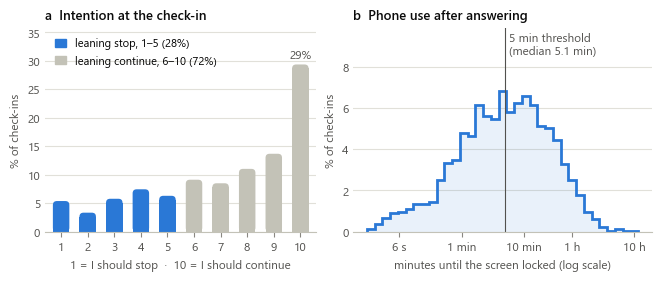

In [5]:
ans_pct = df.answer.value_counts(normalize=True).sort_index() * 100
stop_share = (df.answer <= 5).mean() * 100

fig, (a, b) = plt.subplots(1, 2, figsize=(6.5, 2.7), layout="constrained", gridspec_kw={"width_ratios": [1, 1.1]})

a.set_xlim(0.4, 10.6)
a.set_ylim(0, ans_pct.max() * 1.22)
a.set_xticks(range(1, 11))
a.yaxis.grid(True)
a.set_axisbelow(True)
a.spines["left"].set_visible(False)
a.tick_params(axis="y", length=0)
a.set_title("a  Intention at the check-in", loc="left")
a.set_xlabel("1 = I should stop  ·  10 = I should continue")
a.set_ylabel("% of check-ins")
a.legend(handles=[Patch(color=BLUE, label=f"leaning stop, 1–5 ({stop_share:.0f}%)"),
                  Patch(color=GRAY, label=f"leaning continue, 6–10 ({100 - stop_share:.0f}%)")],
         loc="upper left", handlelength=1.0)
rounded_bars(a, ans_pct.index.values, ans_pct.values, [BLUE if v <= 5 else GRAY for v in ans_pct.index], thickness=0.62)
a.text(10, ans_pct.loc[10] + 0.6, f"{ans_pct.loc[10]:.0f}%", ha="center", va="bottom", color=INK2)

edges = np.logspace(np.log10(0.03), np.log10(700), 36)
counts, _ = np.histogram(df.remaining_minutes, bins=edges)
pct = counts / counts.sum() * 100
b.set_xscale("log")
b.stairs(pct, edges, fill=True, color=BLUE, alpha=0.10, linewidth=0)
b.stairs(pct, edges, color=BLUE, linewidth=2)
b.axvline(5, color=INK2, linewidth=0.8)
med = df.remaining_minutes.median()
b.set_ylim(0, pct.max() * 1.45)
b.text(5 * 1.15, pct.max() * 1.42, f"5 min threshold\n(median {med:.1f} min)", color=INK2, va="top")
b.set_xticks([0.1, 1, 10, 60, 600])
b.set_xticklabels(["6 s", "1 min", "10 min", "1 h", "10 h"])
b.minorticks_off()
b.yaxis.grid(True)
b.set_axisbelow(True)
b.spines["left"].set_visible(False)
b.tick_params(axis="y", length=0)
b.set_title("b  Phone use after answering", loc="left")
b.set_xlabel("minutes until the screen locked (log scale)")
b.set_ylabel("% of check-ins")

fig.savefig(FIG / "fig1_said_vs_did.png")
plt.show()

In [6]:
# What happened after each answer (feeds the interactive supplement; no figure)
assert (df.answer == df.answer.round()).all() and df.answer.between(1, 10).all()
after = df.assign(answer=df.answer.astype(int), over5=df.remaining_minutes > 5)
by_answer = after.groupby("answer").agg(n=("over5", "size"), over5_pct=("over5", "mean"), median_min=("remaining_minutes", "median"))
by_answer["over5_pct"] *= 100
by_answer.insert(1, "share_pct", by_answer.n / len(df) * 100)
SUMMARY["by_answer"] = {
    "definition": "per stated intention: check-ins, share of all check-ins, % followed by more than 5 more minutes of use, median further minutes",
    "rows": records(by_answer, 1),
    "stop_leaning_over5_pct": after.over5[after.answer <= 5].mean() * 100,
    "continue_leaning_over5_pct": after.over5[after.answer >= 6].mean() * 100,
}
print(by_answer.round(1).to_string())
print(f"> 5 more minutes after answering: leaning stop (1-5) {SUMMARY['by_answer']['stop_leaning_over5_pct']:.1f}% "
      f"vs leaning continue (6-10) {SUMMARY['by_answer']['continue_leaning_over5_pct']:.1f}%")


           n  share_pct  over5_pct  median_min
answer                                        
1        311        5.4       26.7         1.3
2        193        3.3       50.3         5.1
3        334        5.8       64.1        12.0
4        430        7.4       61.9         9.6
5        364        6.3       54.7         6.2
6        527        9.1       46.9         4.6
7        491        8.5       45.0         3.9
8        637       11.0       47.3         4.4
9        790       13.7       50.6         5.1
10      1695       29.4       55.5         5.9
> 5 more minutes after answering: leaning stop (1-5) 52.6% vs leaning continue (6-10) 50.9%


## 5. When does the gap happen? Hour of day and weekday (Figure 2)

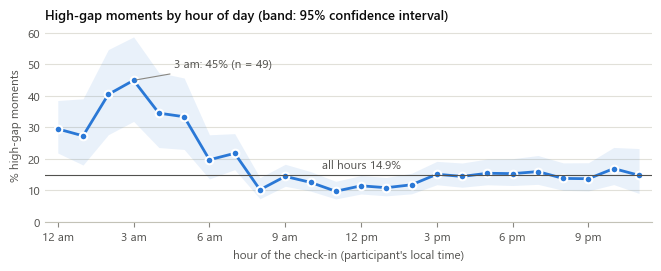

,n,high_gap_pct,mean_ibg,mean_answer
esm_time_period,,,,
afternoon,2243,12.88,-0.29,7.34
evening,987,14.69,-0.03,7.25
morning,1898,13.28,0.01,7.01
night,644,26.86,1.02,6.34


,n,high_gap_pct
esm_is_weekend,,
0,4176,14.70
1,1596,15.35


In [7]:
hour = df.groupby("esm_hour").high_gap.agg(["sum", "size"])
hour["pct"] = hour["sum"] / hour["size"] * 100
lo, hi = wilson(hour["sum"], hour["size"])
hour["ci_lo"], hour["ci_hi"] = lo * 100, hi * 100

fig, ax = plt.subplots(figsize=(6.5, 2.6), layout="constrained")
ax.fill_between(hour.index, hour.ci_lo, hour.ci_hi, color=BLUE, alpha=0.10, linewidth=0)
ax.plot(hour.index, hour.pct, color=BLUE, linewidth=2, solid_joinstyle="round", solid_capstyle="round")
ax.plot(hour.index, hour.pct, "o", color=BLUE, markersize=5.5, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axhline(HG, color=INK2, linewidth=0.8)
ax.text(12, HG + 1.0, f"all hours {HG:.1f}%", ha="center", va="bottom", color=INK2)
peak = hour.pct.idxmax()
ax.annotate(f"{hour_label(peak)}: {hour.pct.max():.0f}% (n = {hour.loc[peak, 'size']})",
            xy=(peak, hour.pct.max()), xytext=(peak + 1.6, hour.pct.max() + 4), color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, hour.ci_hi.max() * 1.05)
ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels([hour_label(h) for h in range(0, 24, 3)])
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("High-gap moments by hour of day (band: 95% confidence interval)", loc="left")
ax.set_xlabel("hour of the check-in (participant's local time)")
ax.set_ylabel("% high-gap moments")
fig.savefig(FIG / "fig2_by_hour.png")
plt.show()

period = df.groupby("esm_time_period").agg(n=("high_gap", "size"), high_gap_pct=("high_gap", "mean"), mean_ibg=("intention_behavior_gap", "mean"), mean_answer=("answer", "mean"))
period["high_gap_pct"] *= 100
weekend = df.groupby("esm_is_weekend").agg(n=("high_gap", "size"), high_gap_pct=("high_gap", "mean"))
weekend["high_gap_pct"] *= 100
display(period.round(2), weekend.round(2))
night_hours = hour.loc[[0, 1, 2, 3, 4, 5]]
SUMMARY["time"] = {
    "by_hour": records(hour), "by_period": records(period), "by_weekend": records(weekend),
    "peak_hour": int(peak), "peak_pct": hour.pct.max(), "peak_n": int(hour.loc[peak, "size"]),
    "hours_0_5_pct": night_hours["sum"].sum() / night_hours["size"].sum() * 100,
    "hours_0_5_n": int(night_hours["size"].sum()),
    "daytime_9_17_pct": hour.loc[9:17, "sum"].sum() / hour.loc[9:17, "size"].sum() * 100,
    "hour_n_min": int(hour["size"].min()), "hour_n_max": int(hour["size"].max()),
}

## 6. Which apps? (Figure 3)

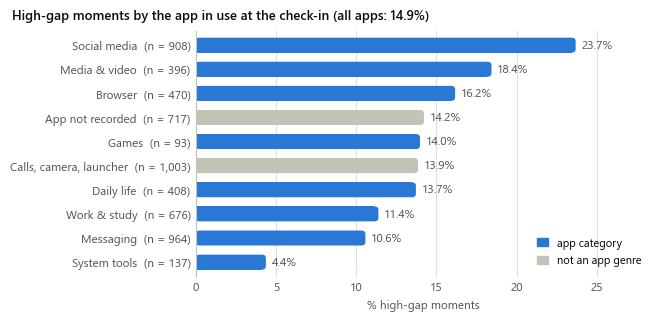

,n,k,mean_ibg,mean_answer,pct
cat,,,,,
System tool,137,6,-1.00,7.97,4.38
Message,964,102,-0.05,6.83,10.58
Work & Study,676,77,-0.48,7.64,11.39
Daily Life,408,56,-0.18,7.18,13.73
To exclude,1003,139,-0.12,7.01,13.86
Game,93,13,-0.22,7.82,13.98
None,717,102,-0.20,7.31,14.23
Browser,470,76,-0.09,7.34,16.17
Media,396,73,0.32,6.97,18.43


In [8]:
names = {"Message": "Messaging", "Social": "Social media", "Work & Study": "Work & study", "Browser": "Browser",
         "Daily Life": "Daily life", "Media": "Media & video", "System tool": "System tools", "Game": "Games",
         "To exclude": "Calls, camera, launcher", "None": "App not recorded"}
technical = {"To exclude", "None"}
cat = df.assign(cat=df.Category_L1.fillna("None")).groupby("cat").agg(
    n=("high_gap", "size"), k=("high_gap", "sum"), mean_ibg=("intention_behavior_gap", "mean"), mean_answer=("answer", "mean"))
cat["pct"] = cat.k / cat.n * 100
cat = cat.sort_values("pct")

fig, ax = plt.subplots(figsize=(6.5, 3.1), layout="constrained")
y = np.arange(len(cat))
ax.set_ylim(-0.6, len(cat) - 0.4)
ax.set_xlim(0, cat.pct.max() * 1.2)
ax.set_yticks(y)
ax.set_yticklabels([f"{names.get(i, i)}  (n = {n:,})" for i, n in zip(cat.index, cat.n)])
ax.tick_params(axis="y", length=0)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", length=0)
rounded_bars(ax, y, cat.pct.values, [GRAY if i in technical else BLUE for i in cat.index], horizontal=True, thickness=0.62)
for yy, v in zip(y, cat.pct):
    ax.text(v + 0.35, yy, f"{v:.1f}%", va="center", color=INK2)
ax.legend(handles=[Patch(color=BLUE, label="app category"), Patch(color=GRAY, label="not an app genre")],
          loc="lower right", handlelength=1.0)
fig.suptitle(f"High-gap moments by the app in use at the check-in (all apps: {HG:.1f}%)",
             x=0.01, ha="left", fontsize=9.5, fontweight="semibold", color=INK)
ax.set_xlabel("% high-gap moments")
fig.savefig(FIG / "fig3_by_app_category.png")
plt.show()
display(cat.round(2))
SUMMARY["app_category"] = records(cat)

## 7. Daily screen time by age group, and elapsed session time (Figure 4)

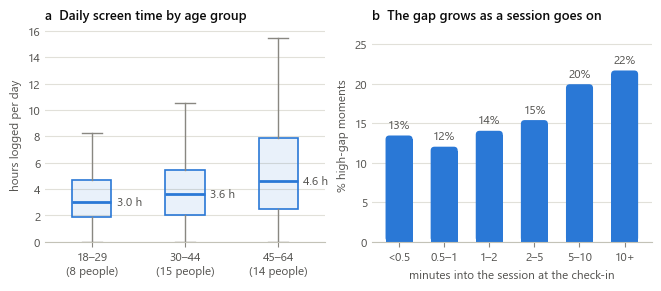

In [9]:
AGE_BANDS = ["18–29", "30–44", "45–64"]
day = df.groupby(["pid", "date_4am"]).agg(screen_min=("screen_time_minutes", "max"), age=("Age", "first")).reset_index()
day["age_band"] = pd.cut(day.age, [17, 29, 44, 64], labels=AGE_BANDS)
people_per_band = df.groupby(pd.cut(df.Age, [17, 29, 44, 64], labels=AGE_BANDS), observed=True).pid.nunique()
hours_by_band = [day.loc[day.age_band == b, "screen_min"].values / 60 for b in AGE_BANDS]

bins = [0, 0.5, 1, 2, 5, 10, np.inf]
blabels = ["<0.5", "0.5–1", "1–2", "2–5", "5–10", "10+"]
df["elapsed_bin"] = pd.cut(df.session_minutes, bins, labels=blabels, right=False)
eb = df.groupby("elapsed_bin", observed=True).high_gap.agg(["sum", "size"])
eb["pct"] = eb["sum"] / eb["size"] * 100

fig, (a, b) = plt.subplots(1, 2, figsize=(6.5, 2.8), layout="constrained")
bp = a.boxplot(hours_by_band, widths=0.42, patch_artist=True, showfliers=False,
               medianprops=dict(color=BLUE, linewidth=2),
               boxprops=dict(facecolor=mpl.colors.to_rgba(BLUE, 0.10), edgecolor=BLUE, linewidth=1.2),
               whiskerprops=dict(color=MUTED, linewidth=1), capprops=dict(color=MUTED, linewidth=1))
for i, vals in enumerate(hours_by_band, start=1):
    a.text(i + 0.27, np.median(vals), f"{np.median(vals):.1f} h", va="center", color=INK2)
a.set_xticks([1, 2, 3])
a.set_xticklabels([f"{b}\n({people_per_band[b]} people)" for b in AGE_BANDS])
a.yaxis.grid(True)
a.set_axisbelow(True)
a.spines["left"].set_visible(False)
a.tick_params(axis="y", length=0)
a.set_ylim(bottom=0)
a.set_title("a  Daily screen time by age group", loc="left")
a.set_ylabel("hours logged per day")

b.set_xlim(-0.6, len(eb) - 0.4)
b.set_ylim(0, eb.pct.max() * 1.25)
b.set_xticks(range(len(eb)))
b.set_xticklabels(blabels)
b.yaxis.grid(True)
b.set_axisbelow(True)
b.spines["left"].set_visible(False)
b.tick_params(axis="y", length=0)
rounded_bars(b, np.arange(len(eb)), eb.pct.values, BLUE, thickness=0.6)
for i, v in enumerate(eb.pct):
    b.text(i, v + 0.5, f"{v:.0f}%", ha="center", va="bottom", color=INK2)
b.set_title("b  The gap grows as a session goes on", loc="left")
b.set_xlabel("minutes into the session at the check-in")
b.set_ylabel("% high-gap moments")
fig.savefig(FIG / "fig4_screen_time_and_session_length.png")
plt.show()

SUMMARY["screen_time"] = {
    "participant_days": len(day),
    "median_hours_all": float(np.median(day.screen_min) / 60),
    "median_hours_by_band": {b: float(np.median(v)) for b, v in zip(AGE_BANDS, hours_by_band)},
    "people_per_band": {b: int(people_per_band[b]) for b in AGE_BANDS},
    "note": "lower bound: cumulative screen time at each day's last check-in (4 am day boundary)",
}
SUMMARY["elapsed"] = records(eb)

## 8. Who? Demographic and context breakdowns (tables only)

In [10]:
def breakdown(key):
    t = df.groupby(key, observed=True).agg(n=("high_gap", "size"), people=("pid", "nunique"), high_gap_pct=("high_gap", "mean"),
                                            mean_ibg=("intention_behavior_gap", "mean"), mean_answer=("answer", "mean"),
                                            median_remaining_min=("remaining_minutes", "median"))
    t["high_gap_pct"] *= 100
    return t

age_t = breakdown(pd.cut(df.Age, [17, 29, 44, 64], labels=AGE_BANDS).rename("age_band"))
gender_t = breakdown(df.Gender_encoded.map({0: "female (code 0)", 1: "male (code 1)"}).rename("gender"))
activity_t = breakdown(df.activity_name.fillna("unknown").rename("activity"))
display(age_t.round(2), gender_t.round(2), activity_t.round(2))
SUMMARY["breakdowns"] = {"age": records(age_t), "gender": records(gender_t), "activity": records(activity_t)}

,n,people,high_gap_pct,mean_ibg,mean_answer,median_remaining_min
age_band,,,,,,
18–29,1313,8,12.95,0.52,6.24,2.88
30–44,2218,15,10.87,-0.03,6.95,3.90
45–64,2241,14,19.99,-0.27,7.76,9.74


,n,people,high_gap_pct,mean_ibg,mean_answer,median_remaining_min
gender,,,,,,
female (code 0),3394,22,19.65,0.56,6.76,7.54
male (code 1),2378,15,8.07,-0.79,7.59,3.35


,n,people,high_gap_pct,mean_ibg,mean_answer,median_remaining_min
activity,,,,,,
in_vehicle,27,10,0.00,-1.66,8.56,2.79
on_bicycle,4,3,25.00,-0.81,7.25,3.95
running,6,3,0.00,-1.91,9.50,14.12
still,5157,37,15.38,0.03,7.12,5.39
unknown,131,28,25.95,1.10,5.92,4.41
walking,447,33,6.94,-0.52,7.16,2.56


## 9. How person-specific is the gap? (Figure 5)

ICC(1) is the share of variance that lies **between** participants. A high ICC means one person's moments resemble each other much more than they resemble other people's. That is the empirical case for personalised models (cf. the paper's Table 3, where new-user prediction reached R² 0.035).

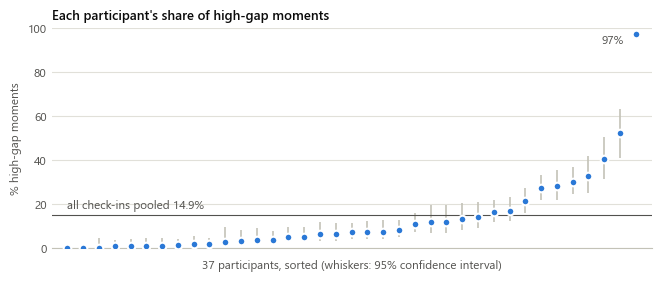

{'ibg': np.float64(0.436), 'intention': np.float64(0.445), 'remaining_log': np.float64(0.27), 'high_gap': np.float64(0.382)}


In [11]:
pp = df.groupby("pid").high_gap.agg(["sum", "size"])
pp["pct"] = pp["sum"] / pp["size"] * 100
pp = pp.sort_values("pct").reset_index()
lo, hi = wilson(pp["sum"], pp["size"])

fig, ax = plt.subplots(figsize=(6.5, 2.7), layout="constrained")
x = np.arange(len(pp))
ax.vlines(x, lo * 100, hi * 100, color=GRAY, linewidth=1.2)
ax.plot(x, pp.pct, "o", color=BLUE, markersize=5.5, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
ax.axhline(HG, color=INK2, linewidth=0.8)
ax.text(0, HG + 1.5, f"all check-ins pooled {HG:.1f}%", va="bottom", color=INK2)
ax.annotate(f"{pp.pct.max():.0f}%", xy=(x[-1], pp.pct.iloc[-1]), xytext=(x[-1] - 2.2, pp.pct.iloc[-1] - 3), color=INK2, va="center")
ax.set_xlim(-1, len(pp))
ax.set_ylim(0, 100)
ax.set_xticks([])
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Each participant's share of high-gap moments", loc="left")
ax.set_xlabel("37 participants, sorted (whiskers: 95% confidence interval)", labelpad=8)
ax.set_ylabel("% high-gap moments")
fig.savefig(FIG / "fig5_per_participant.png")
plt.show()

icc = {name: icc1(df[col], df.pid) for name, col in
       [("ibg", "intention_behavior_gap"), ("intention", "answer"), ("remaining_log", "remaining_log"), ("high_gap", "high_gap")]}
per = df.groupby("pid").answer.agg(share10=lambda s: (s == 10).mean(), sd="std")
print({k: round(v, 3) for k, v in icc.items()})
SUMMARY["person"] = {
    "icc": icc,
    "pp_high_gap_min": pp.pct.min(), "pp_high_gap_q1": pp.pct.quantile(0.25), "pp_high_gap_median": pp.pct.median(),
    "pp_high_gap_q3": pp.pct.quantile(0.75), "pp_high_gap_max": pp.pct.max(),
    "pp_zero_high_gap": int((pp.pct == 0).sum()),
    "raters_mostly_10": int((per.share10 > 0.5).sum()), "max_share_10": per.share10.max(),
}

## 10. Data quality and leakage audit

Columns that must **never** be model inputs. They either *are* the target, are computed from it, reveal the future (when the screen locked), or are identifiers.

In [12]:
leakage = {
    "targets": ["answer", "remaining_scaled", "intention_behavior_gap"],
    "derived from the outcome / future": ["remaining_time", "remaining_minutes", "remaining_capped", "remaining_log", "temp_scaled", "lock_time"],
    "identifiers (grouping only)": ["pid", "PID", "host", "esm_id_full", "session_id_combined", "app_at_prompt", "package_name"],
    "timestamps (ordering only)": ["date", "date_4am", "unlock_time", "esm_time", "esm_local", "unlock_local", "timezone"],
    "exact duplicates (keep one)": ["session_length_till_esm", "time_since_unlock (= session_minutes)", "screen_time_so_far (= screen_time_minutes)"],
}
for k, v in leakage.items():
    print(f"{k}: {', '.join(v)}")
quality = pd.DataFrame([
    ("App fields missing", f"{SUMMARY['dataset']['missing_pct'].get('Category_L1', 0):.1f}% of check-ins ({SUMMARY['dataset']['missing_app_rows']:,})",
     "Keep as an explicit 'app not recorded' category; add a missingness flag"),
    ("Activity missing", f"{SUMMARY['dataset']['missing_pct'].get('activity_type', 0):.1f}%", "'unknown' category"),
    ("Class imbalance", f"high-gap = {HG:.1f}% of check-ins", "PR-AUC / F1, class weights; never accuracy"),
    ("Self-report bias", f"{SUMMARY['person']['raters_mostly_10']} people answer '10' to >50% of prompts", "Per-person standardisation; personal models"),
    ("Skewed outcome", f"remaining time median {SUMMARY['target']['remaining_minutes_median']:.1f} min, max {SUMMARY['target']['remaining_max_minutes']:.0f} min", "Log transform + 128-min cap (as released)"),
    ("Undocumented columns", f"{len(SUMMARY['dataset']['undocumented_columns'])} of 92", "Audited; temp_scaled is outcome-derived (excluded)"),
    ("Small, US-only sample", "37 adults, 5 US time zones", "Participant-level splits; report CIs; state transfer limits"),
], columns=["issue", "evidence", "handling"])
display(quality)
SUMMARY["leakage"] = leakage
SUMMARY["quality_table"] = quality.to_dict(orient="records")

targets: answer, remaining_scaled, intention_behavior_gap
derived from the outcome / future: remaining_time, remaining_minutes, remaining_capped, remaining_log, temp_scaled, lock_time
identifiers (grouping only): pid, PID, host, esm_id_full, session_id_combined, app_at_prompt, package_name
timestamps (ordering only): date, date_4am, unlock_time, esm_time, esm_local, unlock_local, timezone
exact duplicates (keep one): session_length_till_esm, time_since_unlock (= session_minutes), screen_time_so_far (= screen_time_minutes)


,issue,evidence,handling
0,App fields missing,12.4% of check-ins (717),Keep as an explicit 'app not recorded' categor...
1,Activity missing,2.3%,'unknown' category
2,Class imbalance,high-gap = 14.9% of check-ins,"PR-AUC / F1, class weights; never accuracy"
3,Self-report bias,11 people answer '10' to >50% of prompts,Per-person standardisation; personal models
4,Skewed outcome,"remaining time median 5.1 min, max 647 min",Log transform + 128-min cap (as released)
5,Undocumented columns,9 of 92,Audited; temp_scaled is outcome-derived (exclu...
6,"Small, US-only sample","37 adults, 5 US time zones",Participant-level splits; report CIs; state tr...


## 11. Export the numbers used in the report

In [13]:
def to_py(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return round(float(o), 4)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (pd.Timestamp,)):
        return o.isoformat()
    raise TypeError(type(o))

path = OUT / "build" / "eda_summary.json"
path.write_text(json.dumps(SUMMARY, indent=2, default=to_py, ensure_ascii=False), encoding="utf-8")
print("wrote", path, "|", sorted(p.name for p in FIG.glob("*.png")))

wrote ..\deliverables\02_literature_data_technology_review\build\eda_summary.json | ['fig1_said_vs_did.png', 'fig2_by_hour.png', 'fig3_by_app_category.png', 'fig4_screen_time_and_session_length.png', 'fig5_per_participant.png']
